# Machine Learning 934G5 Module Coursework Notebook

## Load Modules

In [71]:
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from torch import nn
import matplotlib.pyplot as plt
import numpy as np
import os
import pickle
import polars as pl
import seaborn as sns
import torch
import torch.optim as optim

In [72]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed = 123
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Data Manipulation

In [73]:
def merge_monthly_dfs(folder):
    """A function to merge monthly csv files from a folder into a single dataframe."""

    dfs = []

    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)

        if not os.path.isfile(filepath):
            continue

        dfs.append(pl.read_csv(filepath))

    df = pl.concat(dfs)

    return df

### Load Data

In [74]:
air_pressure_df = merge_monthly_dfs("data/Psurf_f_inst")
rain_df = merge_monthly_dfs("data/Rainf_tavg")
wind_direction_df = merge_monthly_dfs("data/Wind_dir_p1000")
wind_speed_df = merge_monthly_dfs("data/Wind_f_inst")

In [75]:
dfs = [air_pressure_df, wind_speed_df]

for i, _ in enumerate(dfs):

    # Replace "nan" strings with None
    dfs[i] = dfs[i].with_columns([
        pl.col(c).fill_nan(None) for c in dfs[i].columns
    ])

    cols_to_average = [c for c in dfs[i].columns if c.startswith("data_hour_")]

    # Combine "data_hour_x" columns into a single mean average
    dfs[i] = dfs[i].with_columns(
        pl.mean_horizontal(cols_to_average).alias("mean")
    )

    # drop "data_hour_x" columns
    dfs[i] = dfs[i].drop(cols_to_average)

air_pressure_df, wind_speed_df = dfs

del i, _, cols_to_average

In [76]:
# hourly rain data is to be summed rather than averaged.

rain_df = rain_df.with_columns([
    pl.col(c).fill_nan(None) for c in rain_df.columns
])

cols_to_sum = [c for c in rain_df.columns if c.startswith("data_hour_")]

# Combine "data_hour_x" into single total (sum) column
rain_df = rain_df.with_columns(
    pl.sum_horizontal(cols_to_sum).alias("total")
)

rain_df = rain_df.with_columns(
    (np.log10(pl.col("total") * 1e3)).alias("total")
)

rain_df = rain_df.drop(cols_to_sum)

del cols_to_sum

c:\Users\Charlie\Documents\coding\python\projects\machine-learning-coursework\.venv\Lib\site-packages\polars\series\series.py:1674: RuntimeWarning: divide by zero encountered in log10
  lambda out: ufunc(*args, out=out, dtype=dtype_char, **kwargs),


In [7]:
wind_direction_df = wind_direction_df.with_columns([
    pl.col(c).fill_nan(None) for c in wind_direction_df.columns
])

cols = [c for c in wind_direction_df.columns if c.startswith("data_hour_")]

wind_direction_df = wind_direction_df.with_columns([
    pl.mean_horizontal([pl.col(c).radians().cos() for c in cols]).alias("u_mean"),
    pl.mean_horizontal([pl.col(c).radians().sin() for c in cols]).alias("v_mean"),
])

wind_direction_df = wind_direction_df.with_columns([
    pl.col("u_mean").alias("cos_mean"),
    pl.col("v_mean").alias("sin_mean")
]).drop(["u_mean", "v_mean"] + cols)

In [8]:
dfs = [air_pressure_df, rain_df, wind_direction_df, wind_speed_df]

prefixes = ["air_pressure_", "rain_", "wind_direction_", "wind_speed_"]

# add prefix to mean/total columns to indicate which metric it refers to
dfs = [
    df.rename({col: prefix + col for col in df.columns[5:]}) 
    for df, prefix in zip(dfs, prefixes) 
] 

air_pressure_df, rain_df, wind_direction_df, wind_speed_df = dfs

del prefixes, dfs

In [9]:
# combine separate metric dataframes into a single dataframe

df = (
    air_pressure_df.lazy()
    .join(
        rain_df.lazy(), 
        on=["longitude", "latitude", "year", "month", "day"],
        how="full",
        coalesce=True
    )
    .join(
        wind_direction_df.lazy(), 
        on=["longitude", "latitude", "year", "month", "day"],
        how="full",
        coalesce=True
    )
    .join(
        wind_speed_df.lazy(), 
        on=["longitude", "latitude", "year", "month", "day"],
        how="full",
        coalesce=True
    )
    .collect()
)

del air_pressure_df, rain_df, wind_direction_df, wind_speed_df

In [10]:
df = df.drop_nulls()

In [11]:
# create a single date column from the "year", "month" and "day" columns

df = df.with_columns([
    (pl.col("year") * 10000 + pl.col("month") * 100 + pl.col("day"))
    .cast(pl.Utf8)
    .str.strptime(pl.Date, format="%Y%m%d")
    .alias("date")
])

In [12]:
df = df.with_columns(
    pl.date("year", "month", "day").alias("date")
)

# Extract day-of-year
df = df.with_columns(
    pl.col("date").dt.ordinal_day().alias("day_of_year")
)

In [13]:
df = df.with_columns([
    (pl.col("day_of_year") * 2 * np.pi / 365).sin().alias("day_sin"),
    (pl.col("day_of_year") * 2 * np.pi / 365).cos().alias("day_cos")
])

In [14]:
cols = [
    "wind_speed_mean", 
    "wind_direction_sin_mean", 
    "wind_direction_cos_mean", 
    "rain_total", 
    "air_pressure_mean"
]

In [15]:
# for each date in each location, add a set of columns to indicate the 
# weather metric values 7 days ahead in time

df = df.with_columns(
    [
        pl.col(c)
        .shift(-7)
        .over(["longitude", "latitude"])
        .alias(f"{c}_plus7days")
        for c in cols
    ]
)

In [16]:
# for each date in each location, add a set of columns to indicate the
# weather metric values for the past 14 days (including the current day). 
# 
# Each weather metric will therefore have 13 associated lagged columns 
# (i.e. lag1, ..., lag13).

lag_days = 13

for col in cols:
    lag_exprs = [
        pl.col(col).shift(lag).over(["latitude", "longitude"]).alias(f"{col}_lag{lag}")
        for lag in range(1, lag_days + 1)
    ]
    df = df.with_columns(lag_exprs)

number_of_lag_days_to_use = 6

In [17]:
df = df.drop_nulls()

In [18]:
start_date = df.select(pl.min("date")).item()
end_date = df.select(pl.max("date")).item()

print(f"The model starts at {start_date} and ends as {end_date}")

with open("metadata/start_date.pkl", "wb") as f:
    pickle.dump(start_date.strftime("%Y-%m-%d"), f)

with open("metadata/end_date.pkl", "wb") as f:
    pickle.dump(end_date.strftime("%Y-%m-%d"), f)

The model starts at 2023-01-15 and ends as 2025-08-23


In [19]:
# split data whilst retaining time-series order. 
# 
# Random train-validate-test split would introduce unrealistic data 
# leakage. Instead, this approach simulates a realistic prediction 
# scenario (i.e. the model would be applied to unseen future dates 
# in the real world).
# 
# train = 2023 and 2024
# validate = January-April 2025
# test = May-August 2025

lag_columns = [
    col for col in df.columns
    if any(col.endswith(f"_lag{i}") for i in range(1, number_of_lag_days_to_use + 1))
]

train_X = (
    df
    .filter(pl.col("year") < 2025)
    .select(
        pl.col([
            "latitude",
            "longitude",
            "day_sin",
            "day_cos",
            "air_pressure_mean",
            "rain_total",
            "wind_direction_sin_mean",
            "wind_direction_cos_mean",
            "wind_speed_mean"
        ]),
        pl.col(lag_columns)
    )
    .to_numpy()
)

train_y = (
    df
    .filter(pl.col("year") < 2025)
    .select([
        "air_pressure_mean_plus7days", "rain_total_plus7days", 
        "wind_direction_sin_mean_plus7days", "wind_direction_cos_mean_plus7days", 
        "wind_speed_mean_plus7days"
    ])
    .to_numpy()
)

validate_X = (
    df
    .filter((pl.col("year") == 2025) & (pl.col("month") <= 4))
    .select(
        pl.col([
            "latitude",
            "longitude",
            "day_sin",
            "day_cos",
            "air_pressure_mean",
            "rain_total",
            "wind_direction_sin_mean",
            "wind_direction_cos_mean",
            "wind_speed_mean"
        ]),
        pl.col(lag_columns)
    )
    .to_numpy()
)

validate_y = (
    df
    .filter((pl.col("year") == 2025) & (pl.col("month") <= 4))
    .select([
        "air_pressure_mean_plus7days", "rain_total_plus7days", 
        "wind_direction_sin_mean_plus7days", "wind_direction_cos_mean_plus7days", 
        "wind_speed_mean_plus7days"
    ])
    .to_numpy()
)

test_X = (
    df
    .filter((pl.col("year") == 2025) & (pl.col("month") > 4))
    .select(
        pl.col([
            "latitude",
            "longitude",
            "day_sin",
            "day_cos",
            "air_pressure_mean",
            "rain_total",
            "wind_direction_sin_mean",
            "wind_direction_cos_mean",
            "wind_speed_mean"
        ]),
        pl.col(lag_columns)
    )
    .to_numpy()
)

test_y = (
    df
    .filter((pl.col("year") == 2025) & (pl.col("month") > 4))
    .select([
        "air_pressure_mean_plus7days", "rain_total_plus7days", 
        "wind_direction_sin_mean_plus7days", "wind_direction_cos_mean_plus7days", 
        "wind_speed_mean_plus7days"
    ])
    .to_numpy()
)

In [20]:
# apply min-max scaling to both features and labels
# scaling is applied to outputs as we have 4 regression 
# outputs which have large scaling differences (i.e. 
# air pressure = ~10^5, rain = ~10^-4).

scaler_X = StandardScaler()
scaler_X.fit(train_X)
train_X_scaled = scaler_X.transform(train_X)
validate_X_scaled = scaler_X.transform(validate_X)
test_X_scaled = scaler_X.transform(test_X)

scaler_y = StandardScaler()
scaler_y.fit(train_y)
train_y_scaled = scaler_y.transform(train_y)
validate_y_scaled = scaler_y.transform(validate_y)
test_y_scaled = scaler_y.transform(test_y)

In [37]:
# define MLP hyperparameters, loss function and optimiser

batch_size = 512
dropout = 0.2
epochs = 10
hidden_layer_sizes = [64, 32]
input_size = train_X_scaled.shape[1]
learning_rate = 1e-5
n_test_samples = test_X_scaled.shape[0]
n_train_samples = train_X_scaled.shape[0]
n_validate_samples = validate_X_scaled.shape[0]
output_size = train_y_scaled.shape[1]
weight_decay = 1e-5

# save hyperparameter values as pkl files to use in report
model_hyperparameters = {
    "batch_size": batch_size,
    "dropout": dropout,
    "epochs": epochs,
    "hidden_layer_sizes": hidden_layer_sizes,
    "input_size": input_size,
    "learning_rate": learning_rate,
    "number_of_lag_days": number_of_lag_days_to_use,
    "output_size": output_size,
    "test_sample_size": n_test_samples,
    "train_sample_size": n_train_samples,
    "validate_sample_size": n_validate_samples,
    "weight_decay": weight_decay
}

with open("metadata/model_hyperparameters.pkl", "wb") as f:
    pickle.dump(model_hyperparameters, f)

In [38]:
model_hyperparameters_df = pl.DataFrame({
    "parameter": list(model_hyperparameters.keys()),
    "value": [str(v) for v in model_hyperparameters.values()]
}).with_columns(
    pl.col("parameter").replace({
        "batch_size": "Batch Size",
        "dropout": "Dropout",
        "epochs": "Epochs",
        "hidden_layer_sizes": "Hidden Layer Sizes",
        "input_size": "Input Size",
        "learning_rate": "Learning Rate",
        "number_of_lag_days": "Number of Lagged Days Used",
        "output_size": "Output Size",
        "test_sample_size": "Test Sample Size",
        "train_sample_size": "Train Sample Size",
        "validate_sample_size": "Validate Sample Size",
        "weight_decay": "Weight Decay"
    })
).to_pandas().reset_index(drop=True)

with open("metadata/model_hyperparameters_df.pkl", "wb") as f:
    pickle.dump(model_hyperparameters_df, f)

In [39]:
# construct MLP class

class MultilayerPerceptron(nn.Module):

    def __init__(self, input_size, hidden_layer_sizes, output_size):
        super().__init__()

        layers = []
        prev_size = input_size

        # construct hidden layers
        for size in hidden_layer_sizes:
            layers.append(nn.Linear(prev_size, size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout())
            prev_size = size

        # output layer
        layers.append(nn.Linear(prev_size, output_size))

        self.network = nn.Sequential(*layers)

    def forward(self, inputs):
        return self.network(inputs)

In [50]:
model = MultilayerPerceptron(input_size, hidden_layer_sizes, output_size).to(device)
loss_fn = nn.MSELoss()
optimiser = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

training_losses = []
validation_losses = []

for epoch in range(epochs):
    model.train()
    train_loss = 0

    perm = np.random.default_rng(seed=seed).permutation(n_train_samples)
    X_shuffled = train_X_scaled[perm]
    y_shuffled = train_y_scaled[perm]

    for i in range(0, n_train_samples, batch_size):
        X_batch = X_shuffled[i:i+batch_size]
        y_batch = y_shuffled[i:i+batch_size]

        inputs = torch.from_numpy(X_batch).float().to(device)
        targets = torch.from_numpy(y_batch).float().to(device)

        optimiser.zero_grad()
        outputs = model(inputs)
        loss = loss_fn(outputs, targets)
        loss.backward()
        optimiser.step()

        train_loss += loss.item() * inputs.shape[0]

    train_loss /= n_train_samples

    model.eval()
    val_loss = 0

    with torch.no_grad():
        val_inputs = torch.from_numpy(validate_X_scaled).float().to(device)
        val_targets = torch.from_numpy(validate_y_scaled).float().to(device)

        val_outputs = model(val_inputs)
        loss = loss_fn(val_outputs, val_targets)

        val_loss = loss.item()

    training_losses.append(train_loss)
    validation_losses.append(val_loss)

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

Epoch 1/10 | Train Loss: 1.008583 | Val Loss: 1.322998
Epoch 2/10 | Train Loss: 0.957447 | Val Loss: 1.110128
Epoch 3/10 | Train Loss: 0.928333 | Val Loss: 0.993286
Epoch 4/10 | Train Loss: 0.913215 | Val Loss: 0.949991
Epoch 5/10 | Train Loss: 0.903511 | Val Loss: 0.929287
Epoch 6/10 | Train Loss: 0.896858 | Val Loss: 0.917605
Epoch 7/10 | Train Loss: 0.891183 | Val Loss: 0.910331
Epoch 8/10 | Train Loss: 0.887083 | Val Loss: 0.904514
Epoch 9/10 | Train Loss: 0.883102 | Val Loss: 0.898730
Epoch 10/10 | Train Loss: 0.880513 | Val Loss: 0.895955


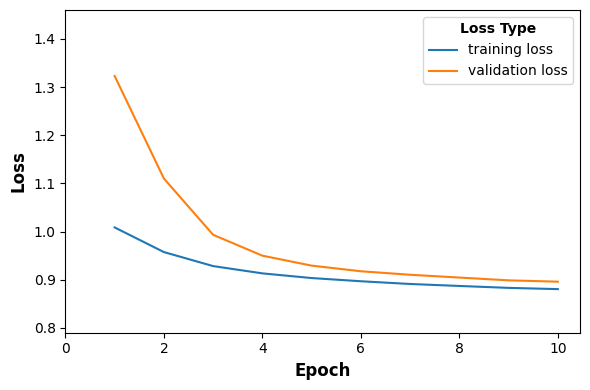

In [51]:
# plot loss vs epoch

epoch_list = [epoch+1 for epoch in range(epochs)]

loss_plot_df = pl.DataFrame({
    "epoch": epoch_list,
    "training loss": training_losses,
    "validation loss": validation_losses
})

long_loss_plot_df = loss_plot_df.unpivot(
    index="epoch",
    on=["training loss", "validation loss"],
    variable_name="loss type",
    value_name="loss",
)

plt.figure(figsize=(6,4))

sns.lineplot(
    data=long_loss_plot_df,
    x="epoch",
    y="loss",
    hue="loss type"
)

plt.legend(title="Loss Type", title_fontproperties={"weight": "bold"})

plt.xlabel("Epoch", weight="bold", size=12)
plt.ylabel("Loss", weight="bold", size=12)

plt.xlim(left=1)
plt.xticks(np.arange(0,epochs+1, 2))
plt.ylim(
    bottom=round(0.9*long_loss_plot_df["loss"].min(), 2), 
    top=round(1.1*long_loss_plot_df["loss"].max(), 2)
)

plt.tight_layout()
plt.savefig("figures/loss_plot.png", dpi=600)
plt.show()

In [52]:
test_preds = []

for i in range(0, test_X_scaled.shape[0], batch_size):
    inputs = torch.from_numpy(test_X_scaled[i:i+batch_size]).float().to(device)
    with torch.no_grad():
        outputs = model(inputs)
    test_preds.append(outputs.cpu().numpy())

test_outputs_scaled = np.concatenate(test_preds, axis=0)
test_outputs = scaler_y.inverse_transform(test_outputs_scaled)

In [54]:
labels = ["air_pressure", "rain", "wind_direction_sin", "wind_direction_cos", "wind_speed"]
means = [round(df[label + "_mean"].mean(), 3) if label != "rain" else round(df[label + "_total"].mean(), 3) for label in labels]
stds = [round(df[label + "_mean"].std(), 3) if label != "rain" else round(df[label + "_total"].std(), 3) for label in labels]
rmse = []

for i, target in enumerate(labels):
    rmse.append(round(np.sqrt(mean_squared_error(test_y[:,i], test_outputs[:,i])), 3))

test_results_df = pl.DataFrame(
    data={
        "Label": labels,
        "RMSE": rmse,
        "Mean": means,
        "Std. Deviation": stds,
        "RMSE / Std. Dev": np.array(rmse) / np.array(stds)
    }
).to_pandas().reset_index(drop=True)

with open("metadata/test_results_df.pkl", "wb") as f:
    pickle.dump(test_results_df.round(3).astype(str), f)

<Axes: xlabel='rain_total', ylabel='Count'>

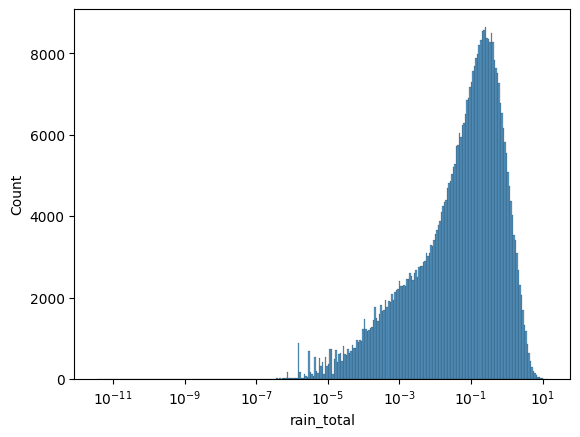

In [64]:
worst_performing_vars_df = df.select(pl.col(["wind_direction_sin_mean", "wind_direction_cos_mean", "rain_total"]))

plt.figure()
sns.histplot(
    data=worst_performing_vars_df,
    x="rain_total",
    log_scale=True
)